
# Cuando el camino más corto no es el mejor

Ruta de evacuación en una zona inundada 
Equipo: CafeSmart
Integrantes:
Morales Mendez Shryley Nicoles
Jimenez Andrade Monserrat
Tejero Hernandez Rubi
Sarao Morales Rubi

Un agente debe ir de un punto inicial a un refugio sobre un terreno con celdas secas, de inundación leve / media / alta (transitables pero riesgosas) y bloqueadas. Se comparan cuatro estrategias (BFS, Dijkstra, A*, Voraz) con ejecuciones reales.

Índice: 
· 1 Modelo 
· 2 Algoritmos 
· 3 Validador 
· 4 Escenario y visualización
 · 5 Comparación 
 · 6 Pruebas (T1–T5) 
 · 7 Prueba adicional (T6) 
 · 8 Decisiones y declaración de IA

## 1. Modelo del terreno
Cada celda tiene un nivel: 0 seco, 1 leve, 2 media, 3 alta, 4 bloqueado.

- **Bloqueo = restricción dura:** las celdas nivel 4 nunca se expanden.
- **Riesgo = costo blando:** costo de entrar a una celda = `1 + λ · riesgo(nivel)`, con riesgo 0, 1, 3, 10. El "1" es el esfuerzo de dar un paso; el resto penaliza el peligro. La penalización no es lineal para que una celda alta pese más que varias leves.
- **Movimiento en 4 direcciones** (sin diagonales, para evitar "cortar esquinas" entre bloqueos).
- **Costos ≥ 1**, así la distancia Manhattan nunca sobreestima el costo restante (heurística admisible para A*).

In [1]:
import heapq, time, random
from collections import deque

# Niveles de terreno
DRY, LOW, MID, HIGH, BLOCKED = 0, 1, 2, 3, 4
# Penalización de riesgo por entrar a una celda (sumada al costo base 1)
RISK_W = {DRY: 0, LOW: 1, MID: 3, HIGH: 10}
MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]  # 4-conectividad


def cell_cost(level, lam=1.0, w=RISK_W):
    """Costo de ENTRAR a una celda: 1 + lam * riesgo. None si bloqueada."""
    if level == BLOCKED:
        return None
    return 1.0 + lam * w[level]


def neighbors(grid, pos):
    r, c = pos
    for dr, dc in MOVES:
        nr, nc = r + dr, c + dc
        if 0 <= nr < len(grid) and 0 <= nc < len(grid[0]) and grid[nr][nc] != BLOCKED:
            yield (nr, nc)


def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def path_cost(grid, path, lam=1.0, w=RISK_W):
    return sum(cell_cost(grid[r][c], lam, w) for r, c in path[1:])


def _rebuild(parent, goal):
    p, cur = [], goal
    while cur is not None:
        p.append(cur)
        cur = parent[cur]
    return p[::-1]


def _result(grid, path, expanded, pushed, t0, lam, w):
    return {
        "path": path,
        "cost": None if path is None else path_cost(grid, path, lam, w),
        "steps": None if path is None else len(path) - 1,
        "expanded": expanded,
        "generated": pushed,
        "time_ms": (time.perf_counter() - t0) * 1000,
    }

## 2. Estrategias de búsqueda
| Estrategia | Optimiza | ¿Ve el riesgo? | Garantía |
|---|---|---|---|
| BFS | número de pasos | No (solo bloqueos) | mínimo de pasos |
| Dijkstra | costo acumulado g(n) | Sí | costo óptimo |
| A* | g(n) + h(n), h = Manhattan | Sí | costo óptimo (h admisible) |
| Voraz | solo h(n) | No | ninguna |

Medida de trabajo: **nodos expandidos** (procesados), **generados** (insertados en la cola) y tiempo.

In [3]:
def bfs(grid, start, goal, lam=1.0, w=RISK_W):
    """Menos pasos; ignora el riesgo (sólo respeta bloqueos)."""
    t0 = time.perf_counter()
    if grid[start[0]][start[1]] == BLOCKED or grid[goal[0]][goal[1]] == BLOCKED:
        return _result(grid, None, 0, 0, t0, lam, w)
    parent, q, exp, gen = {start: None}, deque([start]), 0, 1
    while q:
        cur = q.popleft(); exp += 1
        if cur == goal:
            return _result(grid, _rebuild(parent, goal), exp, gen, t0, lam, w)
        for nb in neighbors(grid, cur):
            if nb not in parent:
                parent[nb] = cur; q.append(nb); gen += 1
    return _result(grid, None, exp, gen, t0, lam, w)

In [4]:
def _best_first(grid, start, goal, lam, w, use_g, h_scale=1.0, use_h=True):
    """Núcleo común de Dijkstra (g), A* (g+h) y Voraz (h)."""
    t0 = time.perf_counter()
    if grid[start[0]][start[1]] == BLOCKED or grid[goal[0]][goal[1]] == BLOCKED:
        return _result(grid, None, 0, 0, t0, lam, w)
    g = {start: 0.0}
    parent = {start: None}
    h = (lambda p: h_scale * manhattan(p, goal)) if use_h else (lambda p: 0.0)
    pq = [(h(start), 0, start)]
    tie, closed, exp, gen = 0, set(), 0, 1
    while pq:
        _, _, cur = heapq.heappop(pq)
        if cur in closed:
            continue
        closed.add(cur); exp += 1
        if cur == goal:
            return _result(grid, _rebuild(parent, goal), exp, gen, t0, lam, w)
        for nb in neighbors(grid, cur):
            ng = g[cur] + cell_cost(grid[nb[0]][nb[1]], lam, w)
            if use_g:
                better = nb not in g or ng < g[nb]
            else:
                better = nb not in g
            if better:
                g[nb] = ng; parent[nb] = cur
                pri = (ng if use_g else 0.0) + h(nb)
                tie += 1
                heapq.heappush(pq, (pri, tie, nb)); gen += 1
    return _result(grid, None, exp, gen, t0, lam, w)


def dijkstra(grid, start, goal, lam=1.0, w=RISK_W):
    return _best_first(grid, start, goal, lam, w, use_g=True, use_h=False)


def astar(grid, start, goal, lam=1.0, w=RISK_W, h_scale=1.0):
    return _best_first(grid, start, goal, lam, w, use_g=True, h_scale=h_scale)


def greedy(grid, start, goal, lam=1.0, w=RISK_W):
    """Voraz: sólo heurística, ignora el costo acumulado y el riesgo."""
    return _best_first(grid, start, goal, lam, w, use_g=False)


ALGOS = {"BFS": bfs, "Dijkstra": dijkstra, "A*": astar, "Voraz": greedy}

## 3. Validador independiente
`validate` recibe una ruta y devuelve las reglas que viola (lista vacía = válida). No depende de los algoritmos, así no hereda sus errores. Comprueba inicio, fin, adyacencia, sin ciclos, sin celdas bloqueadas o fuera del mapa, y que el costo reportado coincida con el recalculado.

In [5]:
def validate(grid, path, start, goal, lam=1.0, w=RISK_W, reported_cost=None):
    """Devuelve lista de violaciones (vacía = ruta válida)."""
    errs = []
    if not path:
        return ["ruta vacía"]
    if path[0] != start: errs.append("no inicia en el punto de partida")
    if path[-1] != goal: errs.append("no termina en el refugio")
    if len(set(path)) != len(path): errs.append("repite celdas (ciclo)")
    for a, b in zip(path, path[1:]):
        if manhattan(a, b) != 1: errs.append(f"salto no adyacente {a}->{b}")
    for r, c in path:
        if not (0 <= r < len(grid) and 0 <= c < len(grid[0])):
            errs.append(f"fuera del mapa {(r, c)}")
        elif grid[r][c] == BLOCKED:
            errs.append(f"atraviesa celda bloqueada {(r, c)}")
    if reported_cost is not None and not errs:
        if abs(path_cost(grid, path, lam, w) - reported_cost) > 1e-9:
            errs.append("el costo reportado no coincide con el recalculado")
    return errs


def risk_profile(grid, path):
    cnt = {k: 0 for k in (DRY, LOW, MID, HIGH)}
    for r, c in path[1:]:
        cnt[grid[r][c]] += 1
    return cnt

## 4. Escenario base y visualización

Un muro bloqueado (columnas 6–8) divide el mapa. Hay un **atajo** por la fila 7 con 3 celdas de inundación alta y un **rodeo seco** por la fila 14. Inicio (7,1), refugio (7,14) (fila, columna).

In [ ]:
# ---------------- Escenarios ----------------
def base_scenario():
    """16x16. Muro inundado (bloqueado) en cols 6-8 con dos pasos:
    atajo por fila 7 (riesgo ALTO) y rodeo seco por fila 14."""
    n = 16
    g = [[DRY] * n for _ in range(n)]
    for r in range(n):
        for c in (6, 7, 8):
            g[r][c] = BLOCKED
    for c in (6, 7, 8):
        g[7][c] = HIGH       # atajo peligroso
        g[14][c] = DRY       # rodeo seguro
    # obstaculo realista: zonas de inundación leve/media
    for r in range(2, 5):
        for c in range(1, 4):
            g[r][c] = LOW
    for r in range(10, 13):
        for c in range(10, 14):
            g[r][c] = MID
    for r in range(3, 6):
        for c in range(11, 14):
            g[r][c] = LOW
    return g, (7, 1), (7, 14)


def random_grid(n, rng, p_block=0.2, p_risk=0.35):
    g = [[DRY] * n for _ in range(n)]
    for r in range(n):
        for c in range(n):
            x = rng.random()
            if x < p_block: g[r][c] = BLOCKED
            elif x < p_block + p_risk: g[r][c] = rng.choice([LOW, MID, HIGH])
    g[0][0] = DRY; g[n - 1][n - 1] = DRY
    return g

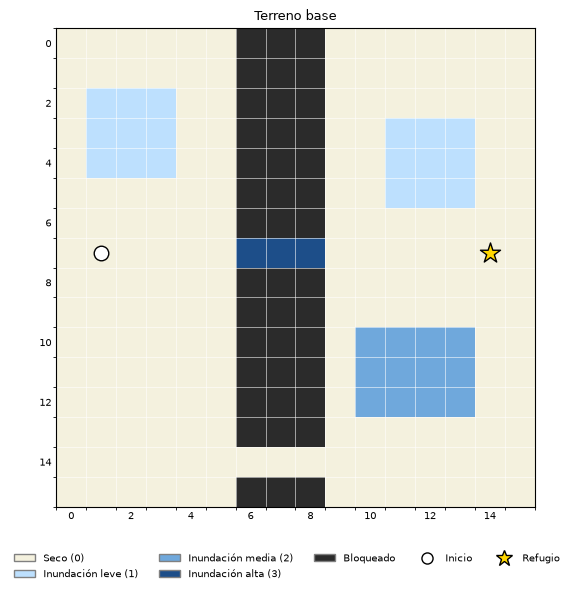

In [6]:
import copy, random, statistics
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

COLORS = ["#f4f1de", "#bde0fe", "#6fa8dc", "#1d4e89", "#2b2b2b"]
CMAP = ListedColormap(COLORS)
PCOL = {"BFS": "#e63946", "Dijkstra": "#2a9d8f", "A*": "#f4a261", "Voraz": "#9b5de5"}

def draw(ax, g, s, t, paths=None, title=""):
    ax.imshow(g, cmap=CMAP, vmin=0, vmax=4)
    n, m = len(g), len(g[0])
    ax.set_xticks([x - .5 for x in range(m + 1)], minor=True)
    ax.set_yticks([y - .5 for y in range(n + 1)], minor=True)
    ax.grid(which="minor", color="white", lw=.4)
    ax.set_xticks(range(0, m, 2)); ax.set_yticks(range(0, n, 2))
    ax.tick_params(labelsize=7, length=0)
    for i, (name, p) in enumerate((paths or {}).items()):
        if p:
            off = (i - (len(paths) - 1) / 2) * 0.12
            ax.plot([c + off for r, c in p], [r + off for r, c in p], color=PCOL[name], lw=2.2)
    ax.scatter([s[1]], [s[0]], marker="o", s=110, c="white", edgecolors="black", zorder=5)
    ax.scatter([t[1]], [t[0]], marker="*", s=230, c="gold", edgecolors="black", zorder=5)
    ax.set_title(title, fontsize=9)

def legend(fig, with_paths=()):
    h = [Patch(fc=COLORS[i], ec="gray", label=l) for i, l in enumerate(
        ["Seco (0)", "Inundación leve (1)", "Inundación media (2)", "Inundación alta (3)", "Bloqueado"])]
    h += [Line2D([0], [0], color=PCOL[k], lw=2.5, label=k) for k in with_paths]
    h += [Line2D([0], [0], marker="o", color="w", mfc="white", mec="black", ms=8, label="Inicio"),
          Line2D([0], [0], marker="*", color="w", mfc="gold", mec="black", ms=12, label="Refugio")]
    fig.legend(handles=h, loc="lower center", ncol=5, fontsize=7.5, frameon=False)

def median_time(fn, g, s, t, lam=1.0, reps=30):
    return statistics.median(fn(g, s, t, lam)["time_ms"] for _ in range(reps))

def compare(g, s, t, lam=1.0):
    """Corre las 4 estrategias, valida cada ruta y devuelve (tabla, rutas)."""
    rows, paths = [], {}
    for k, f in ALGOS.items():
        r = f(g, s, t, lam)
        ok = None
        if r["path"]:
            ok = not validate(g, r["path"], s, t, lam, reported_cost=r["cost"])
        rp = risk_profile(g, r["path"]) if r["path"] else None
        rows.append({"Algoritmo": k, "Costo": r["cost"], "Pasos": r["steps"],
                     "Expandidos": r["expanded"], "Generados": r["generated"],
                     "Tiempo (ms)": round(median_time(f, g, s, t, lam), 3),
                     "Celdas altas": rp[HIGH] if rp else None, "Válida": ok})
        paths[k] = r["path"]
    return pd.DataFrame(rows).set_index("Algoritmo"), paths

g, s, t = base_scenario()
fig, ax = plt.subplots(figsize=(5.5, 5.8))
draw(ax, g, s, t, None, "Terreno base")
fig.tight_layout(rect=[0, 0.1, 1, 1]); legend(fig); plt.show()

## 5. Comparación de estrategias en el escenario base (ejecuciones reales)

,Costo,Pasos,Expandidos,Generados,Tiempo (ms),Celdas altas,Válida
Algoritmo,,,,,,,
BFS,43.0,13,137,150,0.228,3,True
Dijkstra,27.0,27,174,184,0.637,0,True
A*,27.0,27,125,167,0.662,0,True
Voraz,43.0,13,14,35,0.058,3,True


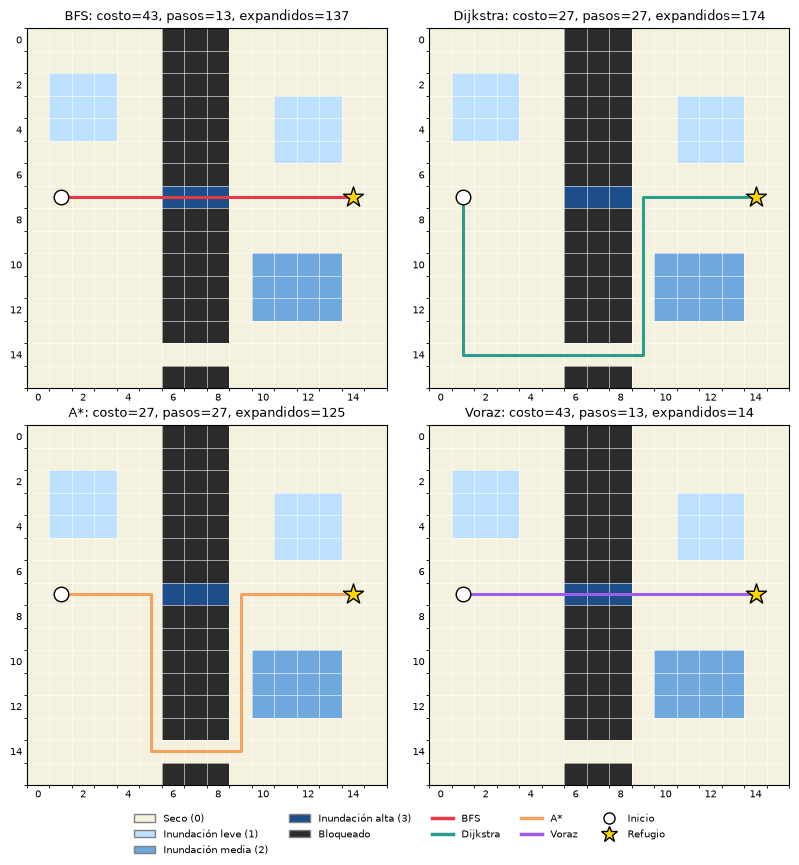

In [7]:
tabla_base, rutas_base = compare(g, s, t)
display(tabla_base)

fig, axs = plt.subplots(2, 2, figsize=(8.2, 8.6))
for ax, k in zip(axs.flat, ALGOS):
    r = tabla_base.loc[k]
    draw(ax, g, s, t, {k: rutas_base[k]}, f"{k}: costo={r['Costo']:.0f}, pasos={r['Pasos']}, expandidos={r['Expandidos']}")
fig.tight_layout(rect=[0, 0.06, 1, 1]); legend(fig, ALGOS); plt.show()

**Pregunta clave: si dos rutas llegan al refugio, una más corta y otra más riesgosa, ¿cómo decide el sistema?**
Compara el costo total Σ(1 + λ·riesgo) de cada ruta y elige el menor. Aquí el atajo cuesta 10·1 + 3·(1+10) = **43** y el rodeo seco 27·1 = **27**, así que gana el rodeo aunque tenga 14 pasos más. Se demuestra con la celda siguiente.

In [8]:
corto, conv = rutas_base["BFS"], rutas_base["Dijkstra"]
print(f"Camino más corto (BFS):        {len(corto)-1} pasos, costo {path_cost(g, corto):.0f}, riesgo {risk_profile(g, corto)}")
print(f"Camino conveniente (Dijkstra): {len(conv)-1} pasos, costo {path_cost(g, conv):.0f}, riesgo {risk_profile(g, conv)}")
assert len(corto) < len(conv)                      # BFS sí es el más corto
assert path_cost(g, conv) < path_cost(g, corto)    # pero NO el más conveniente
assert tabla_base.loc["A*", "Costo"] == tabla_base.loc["Dijkstra", "Costo"]
print("OK: el más corto no es el más conveniente; A* y Dijkstra coinciden en el óptimo.")

Camino más corto (BFS):        13 pasos, costo 43, riesgo {0: 10, 1: 0, 2: 0, 3: 3}
Camino conveniente (Dijkstra): 27 pasos, costo 27, riesgo {0: 27, 1: 0, 2: 0, 3: 0}
OK: el más corto no es el más conveniente; A* y Dijkstra coinciden en el óptimo.


### Sensibilidad al peso del riesgo λ
Con esta geometría el atajo cuesta 13 + 30λ y el rodeo 27 (no depende de λ), así que la decisión debe cambiar en λ = 14/30 ≈ 0.47. Se comprueba corriendo el algoritmo.

,Dijkstra elige,Costo Dijkstra,Costo ruta BFS
λ,,,
0.0,atajo,13.0,13.0
0.4,atajo,25.0,25.0
0.5,rodeo,27.0,28.0
1.0,rodeo,27.0,43.0
2.0,rodeo,27.0,73.0


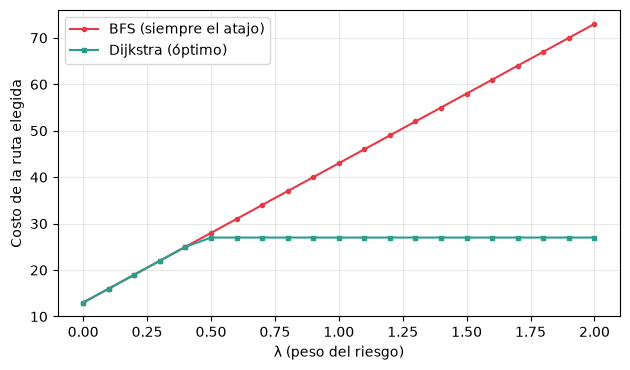

El cambio de decisión ocurre en λ = 0.5


In [9]:
lams = [round(0.1 * i, 1) for i in range(21)]
sweep = []
for lam in lams:
    d, b = dijkstra(g, s, t, lam), bfs(g, s, t, lam)
    sweep.append({"λ": lam, "Dijkstra elige": "atajo" if (7, 7) in d["path"] else "rodeo",
                  "Costo Dijkstra": d["cost"], "Costo ruta BFS": b["cost"]})
sweep = pd.DataFrame(sweep).set_index("λ")
display(sweep.loc[[0.0, 0.4, 0.5, 1.0, 2.0]])

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(lams, sweep["Costo ruta BFS"], color=PCOL["BFS"], marker="o", ms=3, label="BFS (siempre el atajo)")
ax.plot(lams, sweep["Costo Dijkstra"], color=PCOL["Dijkstra"], marker="s", ms=3, label="Dijkstra (óptimo)")
ax.set_xlabel("λ (peso del riesgo)"); ax.set_ylabel("Costo de la ruta elegida"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

primer_rodeo = sweep[sweep["Dijkstra elige"] == "rodeo"].index.min()
assert 0.4 < primer_rodeo <= 0.5, primer_rodeo   # coincide con 14/30 ≈ 0.47 calculado a mano
print("El cambio de decisión ocurre en λ =", primer_rodeo)

## 6. Pruebas
Cada prueba usa `assert`: si el comportamiento es incorrecto, la celda falla.

### T1. Existe una ruta disponible

In [10]:
for k, r in tabla_base.iterrows():
    assert r["Válida"] is True or r["Válida"] == True, k
print("T1 OK: las 4 estrategias devuelven una ruta válida.")

T1 OK: las 4 estrategias devuelven una ruta válida.


### T2. Se bloquea una zona que formaba parte de la ruta

,Costo,Pasos,Expandidos,Generados,Tiempo (ms),Celdas altas,Válida
Algoritmo,,,,,,,
BFS,43.0,13,136,148,0.277,3,True
Dijkstra,43.0,13,131,146,0.887,3,True
A*,43.0,13,106,118,0.426,3,True
Voraz,43.0,13,14,35,0.074,3,True


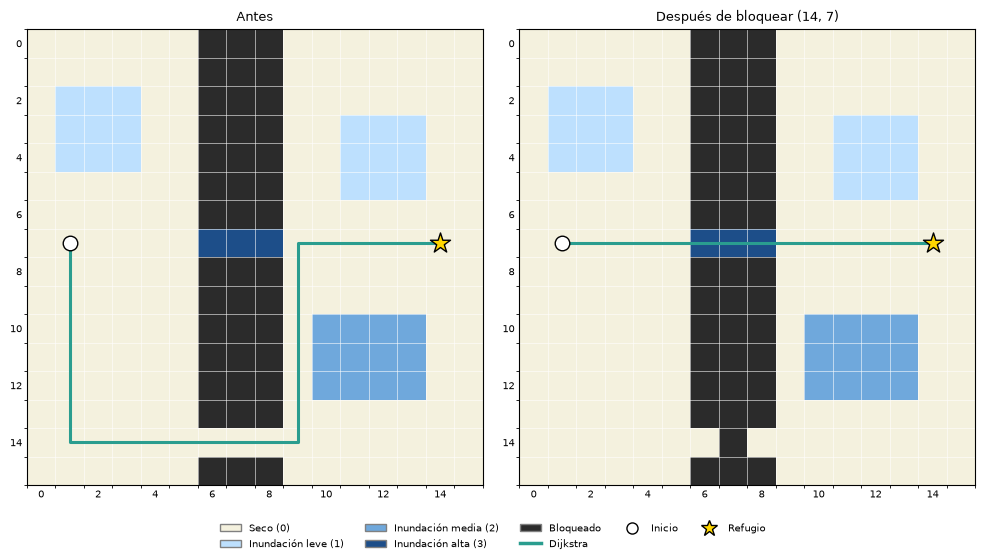

T2 OK: ninguna ruta usa la celda bloqueada; el costo óptimo subió.


In [11]:
g2 = copy.deepcopy(g)
celda = (14, 7)
assert celda in rutas_base["Dijkstra"]
g2[celda[0]][celda[1]] = BLOCKED
tabla2, rutas2 = compare(g2, s, t)
display(tabla2)
for k, p in rutas2.items():
    assert celda not in p, f"{k} atraviesa la celda bloqueada"
assert tabla2.loc["Dijkstra", "Costo"] > tabla_base.loc["Dijkstra", "Costo"]
fig, axs = plt.subplots(1, 2, figsize=(10, 5.4))
draw(axs[0], g, s, t, {"Dijkstra": rutas_base["Dijkstra"]}, "Antes")
draw(axs[1], g2, s, t, {"Dijkstra": rutas2["Dijkstra"]}, f"Después de bloquear {celda}")
fig.tight_layout(rect=[0, 0.1, 1, 1]); legend(fig, ["Dijkstra"]); plt.show()
print("T2 OK: ninguna ruta usa la celda bloqueada; el costo óptimo subió.")

### T3. El refugio deja de ser accesible

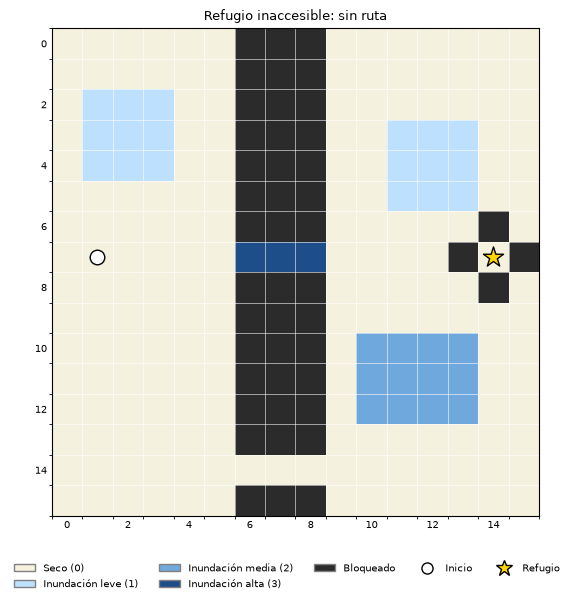

T3 OK: sin ruta (None), sin errores ni ciclos; casos límite correctos.


In [12]:
g3 = copy.deepcopy(g)
for (r, c) in [(6, 14), (8, 14), (7, 13), (7, 15)]:
    g3[r][c] = BLOCKED
for k, f in ALGOS.items():
    assert f(g3, s, t)["path"] is None, k          # refugio encerrado
g3b = copy.deepcopy(g); g3b[t[0]][t[1]] = BLOCKED   # refugio bloqueado
g3c = copy.deepcopy(g); g3c[s[0]][s[1]] = BLOCKED   # inicio bloqueado
for k, f in ALGOS.items():
    assert f(g3b, s, t)["path"] is None and f(g3c, s, t)["path"] is None, k
    r = f(g, s, s)                                  # inicio == refugio
    assert r["steps"] == 0 and r["cost"] == 0, k
fig, ax = plt.subplots(figsize=(5.6, 5.9))
draw(ax, g3, s, t, None, "Refugio inaccesible: sin ruta")
fig.tight_layout(rect=[0, 0.1, 1, 1]); legend(fig); plt.show()
print("T3 OK: sin ruta (None), sin errores ni ciclos; casos límite correctos.")

### T4. Se modifica el riesgo de una región y se repite la búsqueda

,Costo,Pasos,Expandidos,Generados,Tiempo (ms),Celdas altas,Válida
Algoritmo,,,,,,,
BFS,16.0,13,137,150,0.302,0,True
Dijkstra,16.0,13,134,151,0.591,0,True
A*,16.0,13,25,47,0.194,0,True
Voraz,16.0,13,14,35,0.130,0,True


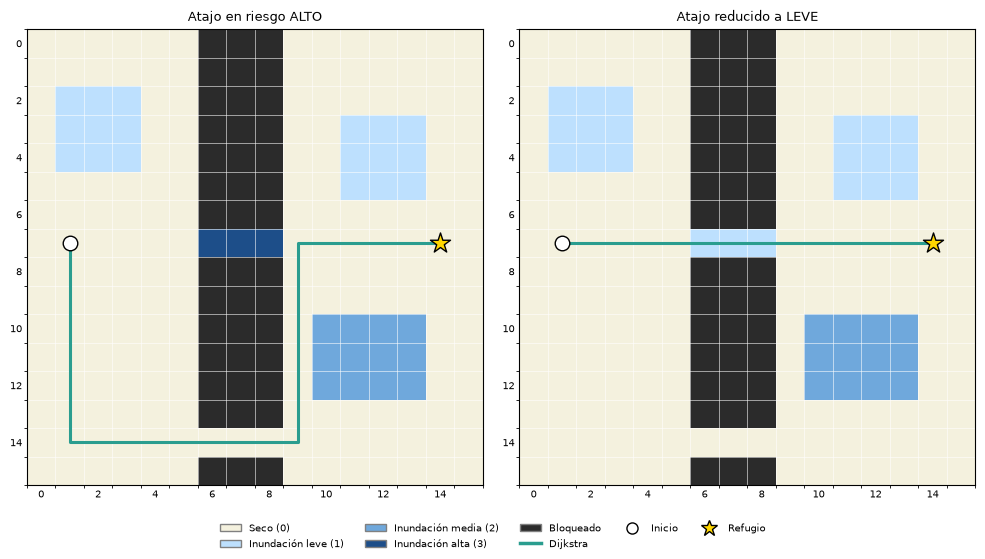

T4 OK: al cambiar solo el riesgo, cambia la decisión.


In [13]:
g4 = copy.deepcopy(g)
for c in (6, 7, 8):
    g4[7][c] = LOW            # el agua bajó: el atajo pasa de ALTO a LEVE
tabla4, rutas4 = compare(g4, s, t)
display(tabla4)
assert (7, 7) in rutas4["Dijkstra"]                      # ahora Dijkstra sí toma el atajo
assert tabla4.loc["Dijkstra", "Costo"] < tabla_base.loc["Dijkstra", "Costo"]
fig, axs = plt.subplots(1, 2, figsize=(10, 5.4))
draw(axs[0], g, s, t, {"Dijkstra": rutas_base["Dijkstra"]}, "Atajo en riesgo ALTO")
draw(axs[1], g4, s, t, {"Dijkstra": rutas4["Dijkstra"]}, "Atajo reducido a LEVE")
fig.tight_layout(rect=[0, 0.1, 1, 1]); legend(fig, ["Dijkstra"]); plt.show()
print("T4 OK: al cambiar solo el riesgo, cambia la decisión.")

### T5. El camino más corto deja de ser la alternativa más conveniente

In [14]:
assert tabla_base.loc["BFS", "Pasos"] < tabla_base.loc["Dijkstra", "Pasos"]
assert tabla_base.loc["BFS", "Costo"] > tabla_base.loc["Dijkstra", "Costo"]
print("T5 OK: BFS = más corto (", tabla_base.loc["BFS","Pasos"], "pasos, costo", tabla_base.loc["BFS","Costo"],
      "); Dijkstra/A* = más conveniente (", tabla_base.loc["Dijkstra","Pasos"], "pasos, costo", tabla_base.loc["Dijkstra","Costo"], ")")

T5 OK: BFS = más corto ( 13 pasos, costo 43.0 ); Dijkstra/A* = más conveniente ( 27 pasos, costo 27.0 )


## 7. Prueba adicional (T6): detectar errores de nuestra propia implementación
No está en la lista del enunciado. Sobre 300 mapas aleatorios (semilla fija) se comprueban propiedades que **siempre** deben cumplirse; una violación revelaría un error real:
1. A* y Dijkstra dan el mismo costo (detecta heurística inadmisible o error en la cola).
2. Toda ruta pasa el validador.
3. BFS nunca usa más pasos que otra estrategia.
4. Las 4 estrategias coinciden en si hay ruta o no.

Para probar que **la prueba sí detecta errores**, se incluye un *mutante*: A* con heurística ×5 (inadmisible), que debe ser delatado.

In [15]:
rng = random.Random(42)
N, size = 300, 14
st = dict(resolubles=0, astar_vs_dijkstra=0, invalidas=0, bfs_no_min=0, alcanz_incons=0, voraz_subopt=0, mutante_subopt=0)
for _ in range(N):
    gr = random_grid(size, rng)
    S, T = (0, 0), (size - 1, size - 1)
    res = {k: f(gr, S, T) for k, f in ALGOS.items()}
    mut = astar(gr, S, T, h_scale=5.0)
    if len({r["path"] is None for r in res.values()}) != 1:
        st["alcanz_incons"] += 1
    if res["Dijkstra"]["path"] is None:
        continue
    st["resolubles"] += 1
    for r in res.values():
        if validate(gr, r["path"], S, T, reported_cost=r["cost"]):
            st["invalidas"] += 1
    if abs(res["A*"]["cost"] - res["Dijkstra"]["cost"]) > 1e-9: st["astar_vs_dijkstra"] += 1
    if res["BFS"]["steps"] > min(r["steps"] for r in res.values()): st["bfs_no_min"] += 1
    if res["Voraz"]["cost"] > res["Dijkstra"]["cost"] + 1e-9: st["voraz_subopt"] += 1
    if mut["cost"] > res["Dijkstra"]["cost"] + 1e-9: st["mutante_subopt"] += 1
print(st)
assert st["astar_vs_dijkstra"] == 0 and st["invalidas"] == 0 and st["bfs_no_min"] == 0 and st["alcanz_incons"] == 0
assert st["mutante_subopt"] > 0, "la prueba NO detectó el mutante: no sirve"
print(f"T6 OK: 0 violaciones en {st['resolubles']} mapas resolubles; el mutante A*(h×5) fue delatado en {st['mutante_subopt']}.")

{'resolubles': 259, 'astar_vs_dijkstra': 0, 'invalidas': 0, 'bfs_no_min': 0, 'alcanz_incons': 0, 'voraz_subopt': 259, 'mutante_subopt': 214}
T6 OK: 0 violaciones en 259 mapas resolubles; el mutante A*(h×5) fue delatado en 214.


In [ ]:
# El validador también debe RECHAZAR rutas malas
buena = dijkstra(g, s, t)["path"]
mala1 = list(buena); mala1[3] = (mala1[3][0] + 1, mala1[3][1] + 1)                  # salto diagonal
mala2 = [(7,1),(7,2),(7,3),(7,4),(7,5),(6,5),(6,6),(6,7),(6,8),(6,9)]                 # cruza el muro
casos = {"salto diagonal": validate(g, mala1, s, t),
         "celda bloqueada": validate(g, mala2, s, (6, 9)),
         "no llega al refugio": validate(g, buena[:-2], s, t),
         "costo falso": validate(g, buena, s, t, reported_cost=5.0)}
for nombre, errs in casos.items():
    assert errs, f"el validador NO rechazó: {nombre}"
    print(f"Rechazada ({nombre}):", errs[0])

Rechazada (salto diagonal): salto no adyacente (9, 1)->(11, 2)
Rechazada (celda bloqueada): atraviesa celda bloqueada (6, 6)
Rechazada (no llega al refugio): no termina en el refugio
Rechazada (costo falso): el costo reportado no coincide con el recalculado
